In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
import string

In [2]:
df = pd.read_csv("sms.csv", encoding="latin1")

In [3]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:
df.shape

(5572, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [6]:
df.drop(columns=["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"], inplace=True)

In [7]:
df.rename(columns={"v1":"target", "v2":"text"}, inplace=True)
df.sample(10)

,target,text
4813,ham,Ummmmmaah Many many happy returns of d day my ...
2148,ham,I will once i get home
3410,ham,Only once then after ill obey all yours.
3609,ham,"Call me. I m unable to cal. Lets meet bhaskar,..."
3038,ham,"Wishing you and your family Merry \X\"" mas and..."
4398,ham,Yes just finished watching days of our lives. ...
2338,ham,"Alright, see you in a bit"
2600,ham,"As usual..iam fine, happy &amp; doing well..:)"
4585,spam,"Mila, age23, blonde, new in UK. I look sex wit..."
1481,ham,"I'm a guy, browsin is compulsory"


In [8]:
encoder = LabelEncoder()

In [9]:
df["target"]=encoder.fit_transform(df["target"])

In [10]:
df.isnull().sum()

,0
target,0
text,0


In [11]:
df.duplicated().sum()

np.int64(403)

In [12]:
df = df.drop_duplicates(keep = 'first')

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.shape

(5169, 2)

In [15]:
df.value_counts("target")

,count
target,
0,4516
1,653


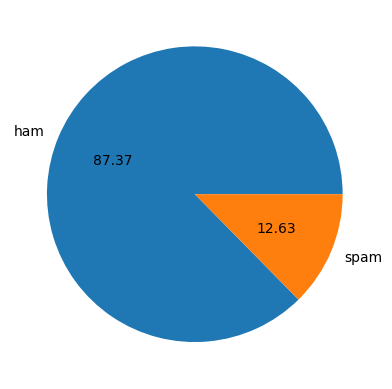

In [16]:
plt.pie(df.value_counts("target"), labels = ['ham','spam'] , autopct = '%0.2f')

plt.show()


In [17]:
import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [18]:
df['num_char']=df['text'].apply(len)

In [19]:
df.sample(5)

,target,text,num_char
4340,0,ÌÏ all write or wat..,21
133,1,Sunshine Quiz Wkly Q! Win a top Sony DVD playe...,126
1712,0,o turns out i had stereo love on mi phone unde...,66
1730,0,Doing project w frens lor.,27
2354,0,R we going with the &lt;#&gt; bus?,36


In [20]:
df['num_word']=df['text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [21]:
df['num_sent']=df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [22]:
df.sample(5)

,target,text,num_char,num_word,num_sent
4162,0,I told that am coming on wednesday.,35,8,1
2650,0,Do you like shaking your booty on the dance fl...,50,11,1
1378,0,"Ya tel, wats ur problem..",25,7,1
4372,0,Me fine..absolutly fine,23,5,1
750,1,"Do you realize that in about 40 years, we'll h...",102,21,1


In [23]:
df[['num_char','num_word','num_sent']].describe()

,num_char,num_word,num_sent
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [24]:
#ham
df[df['target'] ==0][['num_char','num_word','num_sent']].describe()

,num_char,num_word,num_sent
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [25]:
#spam
df[df['target'] ==1][['num_char','num_word','num_sent']].describe()

,num_char,num_word,num_sent
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


<Axes: xlabel='num_char', ylabel='Count'>

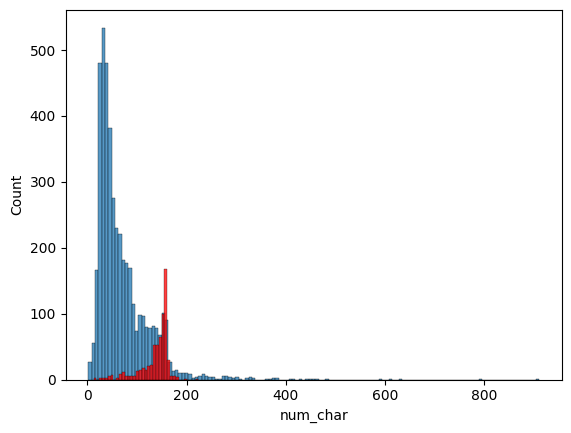

In [26]:
sns.histplot(df[df['target'] ==0]['num_char'])  #ham
sns.histplot(df[df['target'] ==1]['num_char'] , color ='red') #spam

<Axes: xlabel='num_word', ylabel='Count'>

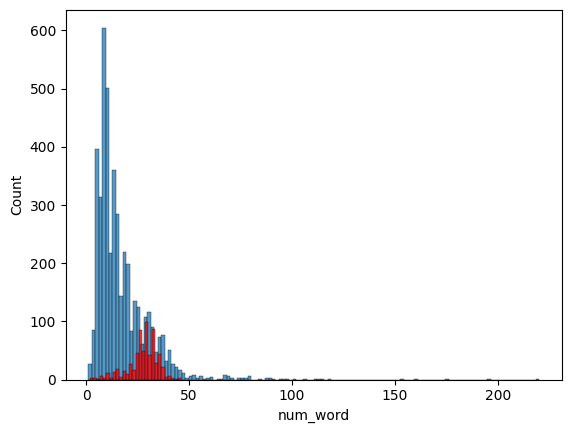

In [27]:
sns.histplot(df[df['target'] ==0]['num_word'])  #ham
sns.histplot(df[df['target'] ==1]['num_word'] , color ='red') #spam

<Axes: xlabel='num_sent', ylabel='Count'>

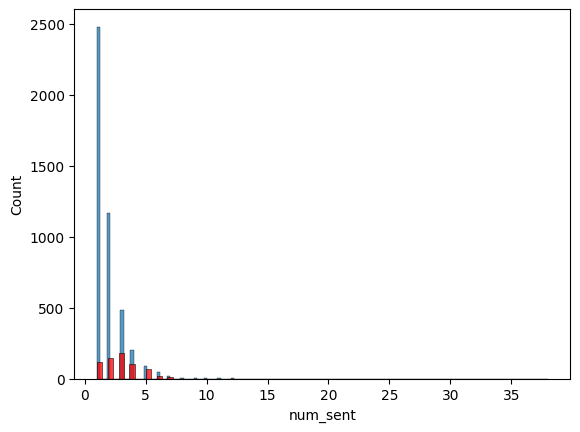

In [28]:
sns.histplot(df[df['target'] ==0]['num_sent'])  #ham
sns.histplot(df[df['target'] ==1]['num_sent'] , color ='red') #spam

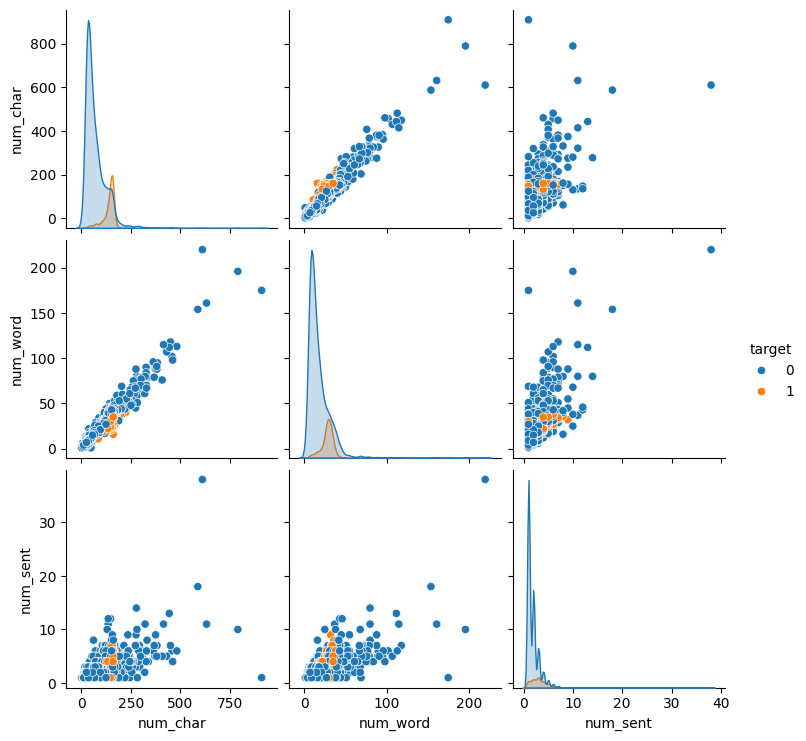

In [29]:
sns.pairplot(df,hue='target')

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5169 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   target    5169 non-null   int64 
 1   text      5169 non-null   object
 2   num_char  5169 non-null   int64 
 3   num_word  5169 non-null   int64 
 4   num_sent  5169 non-null   int64 
dtypes: int64(4), object(1)
memory usage: 242.3+ KB


<Axes: >

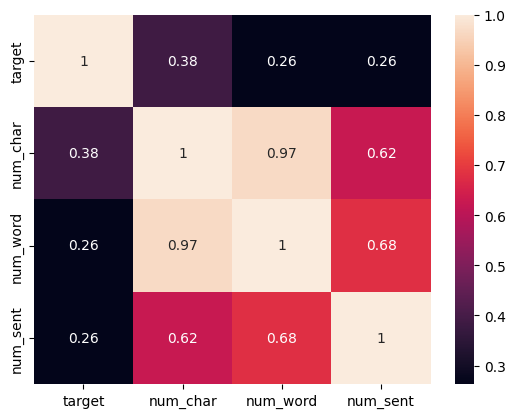

In [31]:
sns.heatmap(df.corr(numeric_only=True), annot=True)


In [32]:
from nltk.corpus import stopwords
nltk.download('stopwords')
stopwords.words('english')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [33]:
def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    y =[]
    for i in text:
        if i.isalnum():
            y.append(i)
    text = y[:]
    y.clear()

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
                y.append(i)
    text = y[:]
    y.clear()

    for i in text:
       y.append(ps.stem(i))


    return " ".join(y)

In [35]:
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()

In [36]:
transform_text('Hi i am Gaurav .i Am learning Ml ')

'hi gaurav learn ml'

In [37]:
ps.stem('fuckking')

'fuck'

In [38]:
df['transformmed_text']=df['text'].apply(transform_text)

In [39]:
df.sample(5)

,target,text,num_char,num_word,num_sent,transformmed_text
4641,1,You are being ripped off! Get your mobile cont...,143,20,2,rip get mobil content call 08717509990 six dow...
2520,0,Misplaced your number and was sending texts to...,179,37,4,misplac number send text old number wonder hea...
4093,0,how are you? I miss you!,24,8,2,miss
79,0,Its not the same here. Still looking for a job...,76,20,3,still look job much ta earn
3974,0,do u think that any girl will propose u today ...,132,21,1,u think girl propos u today se ur bloodi funki...


In [40]:
ps.stem("i  am a GOOD BOY .")

'i  am a good boy .'

In [45]:
from wordcloud import WordCloud

In [46]:
wc = WordCloud(width=500,height=500,min_font_size=10,background_color='white')

In [47]:
spam_wc = wc.generate(df[df['target']==1]['transformmed_text'].str.cat(sep=" "))

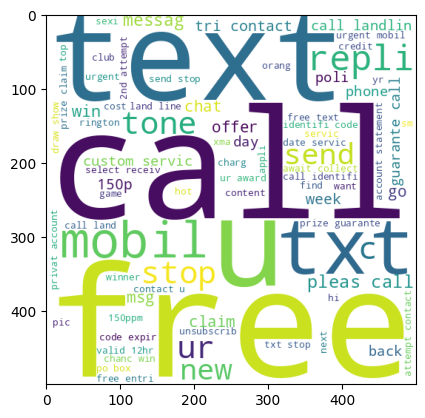

In [48]:
plt.imshow(spam_wc)

In [49]:
ham_wc = wc.generate(df[df['target']==0]['transformmed_text'].str.cat(sep=" "))

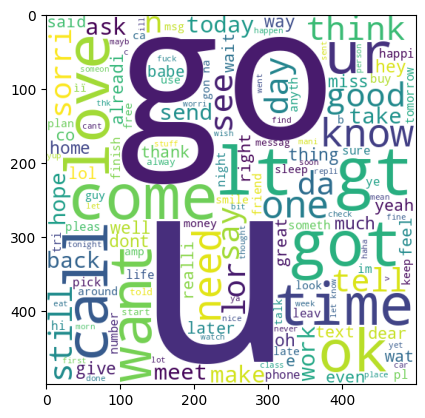

In [50]:
plt.imshow(ham_wc)

In [51]:
spam_corpus = []
for msg in df[df['target']==1]['transformmed_text'].tolist():
    for word in msg.split():
        spam_corpus.append(word)

In [52]:
len(spam_corpus)

9939

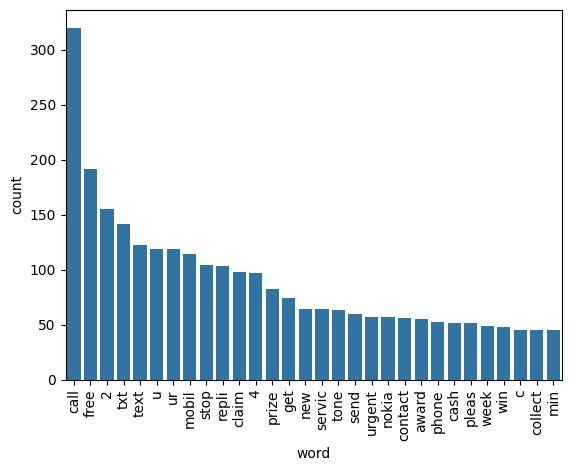

In [62]:
from collections import Counter

# Create a DataFrame for the most common words
spam_words_df = pd.DataFrame(Counter(spam_corpus).most_common(30), columns=['word', 'count'])

# Plot using explicit x and y keywords
sns.barplot(data=spam_words_df, x='word', y='count')
plt.xticks(rotation='vertical')
plt.show()

In [64]:
ham_corpus = []
for msg in df[df['target']==0]['transformmed_text'].tolist():
    for word in msg.split():
        ham_corpus.append(word)

In [65]:
len(ham_corpus)

35404

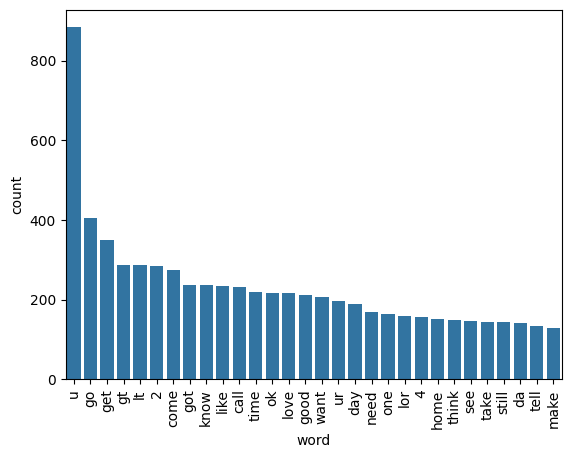

In [66]:
ham_words_df = pd.DataFrame(Counter(ham_corpus).most_common(30), columns=['word', 'count'])
sns.barplot(data=ham_words_df, x='word', y='count')
plt.xticks(rotation='vertical')
plt.show()

MODELS


In [67]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer()

In [68]:
X = cv.fit_transform(df['transformmed_text']).toarray()


In [71]:
X.shape

(5169, 6708)

In [74]:
y = df['target'].values

In [75]:
y.shape

(5169,)

In [76]:
from sklearn.model_selection import train_test_split

In [77]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [80]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score

In [79]:
gnb= GaussianNB()
mnb= MultinomialNB()
bnb= BernoulliNB()

In [91]:
gnb.fit(X_test , y_test)
y_pred1 = gnb.predict(X_test)
print("Accuracy =", accuracy_score(y_test,y_pred1))
print("Precision =",precision_score(y_test,y_pred1))
print("Confusion Matrix =",confusion_matrix(y_test,y_pred1))

Accuracy = 0.9729206963249516
Precision = 0.8313253012048193
Confusion Matrix = [[868  28]
 [  0 138]]


In [92]:
mnb.fit(X_test , y_test)
y_pred2 = mnb.predict(X_test)
print("Accuracy =", accuracy_score(y_test,y_pred2))
print("Precision =",precision_score(y_test,y_pred2))
print("Confusion Matrix =",confusion_matrix(y_test,y_pred2))

Accuracy = 0.9941972920696325
Precision = 0.9925373134328358
Confusion Matrix = [[895   1]
 [  5 133]]


In [93]:
bnb.fit(X_test , y_test)
y_pred3 = bnb.predict(X_test)
print("Accuracy =", accuracy_score(y_test,y_pred3))
print("Precision =",precision_score(y_test,y_pred3))
print("Confusion Matrix =",confusion_matrix(y_test,y_pred3))

Accuracy = 0.8820116054158608
Precision = 1.0
Confusion Matrix = [[896   0]
 [122  16]]


In [95]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

In [103]:
lr = LogisticRegression(solver = 'liblinear', penalty = 'l1')
svc = SVC(kernel='sigmoid', gamma=1.0)
dt = DecisionTreeClassifier(max_depth = 5)
knc = KNeighborsClassifier()
rf = RandomForestClassifier(n_estimators= 50 , random_state = 2)
abc = AdaBoostClassifier(n_estimators= 50 , random_state = 2)
bc = BaggingClassifier(n_estimators= 50 , random_state = 2)
etc = ExtraTreesClassifier(n_estimators= 50 , random_state = 2 )
gbdt = GradientBoostingClassifier(n_estimators= 50 , random_state = 2)
xgb = XGBClassifier(n_estimators= 50 , random_state = 2)

In [104]:
clfs = {
    'SVC' : svc,

    'KN' : knc,
    'DT' : dt,
    'LR' : lr,
    'RF' : rf,
    'AdaBoost' : abc,
    'BgC' : bc,
    'ETC' : etc,
    'GBDT' : gbdt,
    'xgb' : xgb,
    'bnb' : bnb

}

In [105]:
def train_classifier(clf,X_train,y_train,X_test,y_test):
    clf.fit(X_train,y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)

    return accuracy,precision

In [106]:
train_classifier(svc,X_train,y_train,X_test,y_test)

(0.9264990328820116, 0.7421875)

In [107]:
accuracy_scores = []
precision_scores = []
for name,clf in clfs.items():
     current_accuracy,current_precision = train_classifier(clf,X_train,y_train,X_test,y_test)
     print("for", name)
     print("Accuracy =", current_accuracy)
     print("Precision =", current_precision)
     accuracy_scores.append(current_accuracy)
     precision_scores.append(current_precision)

for SVC
Accuracy = 0.9264990328820116
Precision = 0.7421875
for KN
Accuracy = 0.90715667311412
Precision = 1.0
for DT
Accuracy = 0.9235976789168279
Precision = 0.9154929577464789
for LR
Accuracy = 0.9709864603481625
Precision = 0.9736842105263158
for RF
Accuracy = 0.971953578336557
Precision = 1.0
for AdaBoost
Accuracy = 0.9197292069632496
Precision = 0.9365079365079365
for BgC
Accuracy = 0.9622823984526112
Precision = 0.9159663865546218
for ETC
Accuracy = 0.97678916827853
Precision = 0.9913793103448276
for GBDT
Accuracy = 0.9439071566731141
Precision = 0.9444444444444444
for xgb
Accuracy = 0.9738878143133463
Precision = 0.9743589743589743
for bnb
Accuracy = 0.9700193423597679
Precision = 0.9734513274336283


In [118]:
performance_df = pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy':accuracy_scores,'Precision':precision_scores}).sort_values('Precision',ascending=False)

In [119]:
performance_df

,Algorithm,Accuracy,Precision
1,KN,0.907157,1.000000
4,RF,0.971954,1.000000
7,ETC,0.976789,0.991379
9,xgb,0.973888,0.974359
3,LR,0.970986,0.973684
10,bnb,0.970019,0.973451
8,GBDT,0.943907,0.944444
5,AdaBoost,0.919729,0.936508
6,BgC,0.962282,0.915966
2,DT,0.923598,0.915493


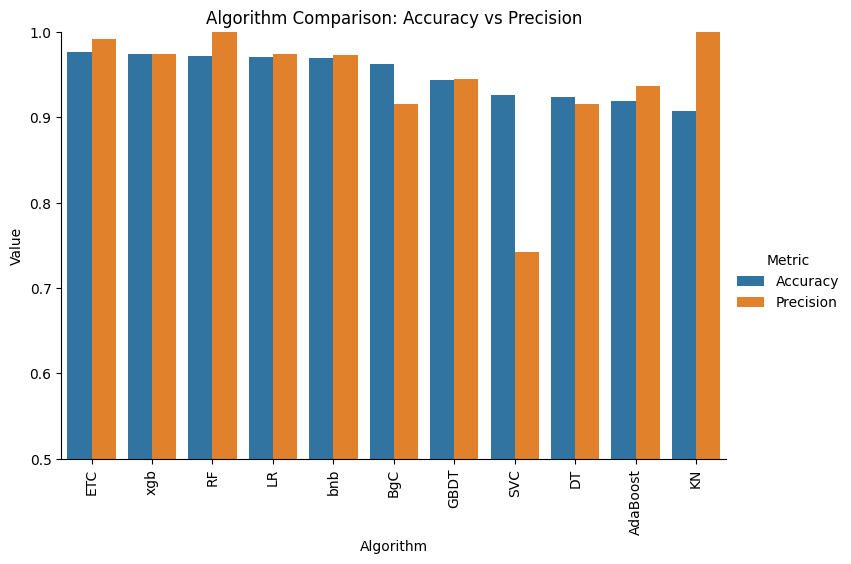

In [116]:
# Melt the performance DataFrame to format it for catplot
performance_melted = pd.melt(performance_df, id_vars="Algorithm", var_name="Metric", value_name="Value")

# Create the catplot using the melted DataFrame
sns.catplot(x='Algorithm', y='Value', hue='Metric', data=performance_melted, kind='bar', height=5, aspect=1.5)
plt.ylim(0.5, 1.0)
plt.xticks(rotation='vertical')
plt.title('Algorithm Comparison: Accuracy vs Precision')
plt.show()

Our best performing algos  are RF(**Random Forest** have p = 1.0000 and A=0.971954) , ETC(**ExtratreesClassifier** have P =0.991379 and A = 0.976789) , XGB( **XGBoosting** have p =0.974359  and A =0.973888) and LR(**Logistic Regression** have P = 0.970986  and A = 0.970986 )

In [120]:
#voting classifier

In [121]:
RF = RandomForestClassifier(n_estimators= 50 , random_state = 2)
ETC = ExtraTreesClassifier(n_estimators= 50 , random_state = 2 )
XGB = XGBClassifier(n_estimators= 50 , random_state = 2)
LR = LogisticRegression(solver = 'liblinear', penalty = 'l1')

In [122]:
from sklearn.ensemble import VotingClassifier

In [123]:
voting_classifier = VotingClassifier(estimators=[('RF', RF), ('ETC', ETC), ('XGB', XGB), ('LR', LR)], voting='soft')

In [124]:
voting_classifier.fit(X_train, y_train)

VotingClassifier(estimators=[('RF',
                              RandomForestClassifier(n_estimators=50,
                                                     random_state=2)),
                             ('ETC',
                              ExtraTreesClassifier(n_estimators=50,
                                                   random_state=2)),
                             ('XGB',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=True,
                                            eva...
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=50, n_jobs=None,
                                            num_parallel_tree=None, ...)),
                             ('LR',
                              LogisticRegression(penalty='l1',
                                                 solver='liblinear'))],
                 voting='soft')

In [125]:
y_pred = voting_classifier.predict(X_test)
print("Accuracy =", accuracy_score(y_test,y_pred))
print("Precision =",precision_score(y_test,y_pred))
print("Confusion Matrix =",confusion_matrix(y_test,y_pred))

Accuracy = 0.97678916827853
Precision = 0.9913793103448276
Confusion Matrix = [[895   1]
 [ 23 115]]


In [126]:
#Stacking

In [128]:
from sklearn.ensemble import StackingClassifier

In [127]:
estimators=[('RF', RF), ('ETC', ETC), ('XGB', XGB), ('LR', LR)]
final_estimator = LogisticRegression()

In [129]:
clf = StackingClassifier(estimators=estimators, final_estimator=final_estimator)

In [130]:
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Accuracy =", accuracy_score(y_test,y_pred))
print("Precision =",precision_score(y_test,y_pred))
print("Confusion Matrix =",confusion_matrix(y_test,y_pred))

Accuracy = 0.9787234042553191
Precision = 0.9603174603174603
Confusion Matrix = [[891   5]
 [ 17 121]]


In [134]:
import pickle
pickle.dump(cv,open('vectorizer.pkl','wb'))
pickle.dump(RF,open('model1.pkl','wb'))